In [1]:
!pip install cudf-cu12 cuml-cu12 --extra-index-url=https://pypi.nvidia.com

Looking in indexes: https://pypi.org/simple, https://pypi.nvidia.com


In [2]:
import cudf
import cuml
import time

def ruleaza_test_gpu(filename):
    print(f"==========================================")
    print(f" TEST GPU PENTRU: {filename}")
    print(f"==========================================")

    # 1. Încărcarea datelor direct în VRAM (Transfer Host-to-Device)
    start_load = time.time()
    gdf = cudf.read_csv(filename)
    timp_load = time.time() - start_load
    print(f"⏬ Timp încărcare în VRAM (I/O): {timp_load:.4f} secunde")

    # 2. Calculul K-Means masiv-paralel pe CUDA
    model_gpu = cuml.cluster.KMeans(n_clusters=4, random_state=42)

    start_fit = time.time()
    model_gpu.fit(gdf)
    timp_fit = time.time() - start_fit

    print(f" Timp Execuție GPU (Calcul brut): {timp_fit:.4f} secunde\n")

# Rulăm testele pentru a demonstra scalabilitatea
ruleaza_test_gpu('date_100k.csv')
ruleaza_test_gpu('date_1m.csv')
ruleaza_test_gpu('date_5m.csv')

 TEST GPU PENTRU: date_100k.csv
⏬ Timp încărcare în VRAM (I/O): 0.9141 secunde
 Timp Execuție GPU (Calcul brut): 1.0993 secunde

 TEST GPU PENTRU: date_1m.csv
⏬ Timp încărcare în VRAM (I/O): 0.0469 secunde
 Timp Execuție GPU (Calcul brut): 0.3372 secunde

 TEST GPU PENTRU: date_5m.csv
⏬ Timp încărcare în VRAM (I/O): 0.0800 secunde
 Timp Execuție GPU (Calcul brut): 0.8953 secunde



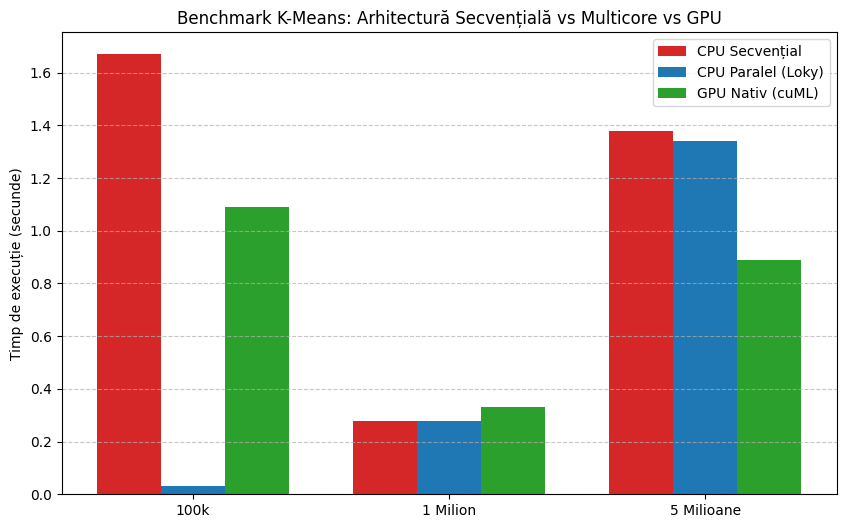

In [3]:
import matplotlib.pyplot as plt
import numpy as np

# Datele extrase din terminal (în secunde)
labels = ['100k', '1 Milion', '5 Milioane']
timp_seq = [1.67, 0.28, 1.38]
timp_par = [0.03, 0.28, 1.34]
timp_gpu = [1.09, 0.33, 0.89]

x = np.arange(len(labels))
width = 0.25

fig, ax = plt.subplots(figsize=(10, 6))
ax.bar(x - width, timp_seq, width, label='CPU Secvențial', color='#d62728')
ax.bar(x, timp_par, width, label='CPU Paralel (Loky)', color='#1f77b4')
ax.bar(x + width, timp_gpu, width, label='GPU Nativ (cuML)', color='#2ca02c')

ax.set_ylabel('Timp de execuție (secunde)')
ax.set_title('Benchmark K-Means: Arhitectură Secvențială vs Multicore vs GPU')
ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.legend()
ax.grid(axis='y', linestyle='--', alpha=0.7)

# Salvăm sau afișăm (în Colab plt.show() randează direct imaginea)
plt.show()